# Tema 13 · Modelos de Clasificación — Guía 5: Sistema de Recomendaciones de Bolsa con Clasificación (Walk-Forward, Costos y Tablero)
**Curso:** Minería de Datos en Python (DM) · FISI · UNMSM · 2026-II · **Laboratorio 12 · Guía 5** · Docente: Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Objetivo:** convertir un clasificador en un **sistema de recomendaciones** para un portafolio de 10 activos: cada viernes, la **probabilidad de que un activo supere a la mediana del portafolio en las próximas 5 sesiones** se traduce en una señal (**COMPRAR / MANTENER / EVITAR**). Se valida con **walk-forward** (reentrenar a medida que avanza el tiempo), se simula con **costos de transacción** y se compara con tres referencias: **1/N**, **SPY** y **portafolios al azar**. El resultado se exporta a un **tablero**.

**Datos:** Yahoo Finance (28 activos, hasta el 19-nov-2026) con respaldo en CSV. **Todo es material educativo; no es asesoría de inversión.**

# 1. Importación de librerías y carga de datos

In [1]:
# Librerías del laboratorio
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")
SEMILLA = 2026  # semilla global: reproducibilidad
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update(
    {"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"}
)

In [2]:
# Librerías de esta guía
import json
from xgboost import XGBClassifier

In [3]:
# Precios ajustados de 28 activos hasta el cierre del 19-nov-2026. Si los 4 CSV del curso (carpeta D03) están junto al notebook se usan
# (las cifras coinciden con las de la guía); si no, se descargan de Yahoo Finance (pueden variar en centésimas si Yahoo revisó precios)
import os

TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = {
    "cierres": "26.11.20.cierres_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "altos": "26.11.20.altos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "bajos": "26.11.20.bajos_ajustados_28_activos_2010-01-04_2026-11-19.csv",
    "volumenes": "26.11.20.volumenes_28_activos_2010-01-04_2026-11-19.csv",
}
if all(os.path.exists(f) for f in ARCH.values()):
    cierres, altos, bajos, volumenes = [
        pd.read_csv(ARCH[k], index_col=0, parse_dates=True)
        for k in ["cierres", "altos", "bajos", "volumenes"]
    ]
    print("Se usó la foto de datos del curso (CSV)")
else:
    try:
        d = yf.download(
            TICKERS,
            start="2010-01-01",
            end="2026-11-20",
            auto_adjust=True,
            progress=False,
        )
        cierres, altos, bajos, volumenes = [
            d[c].reindex(columns=TICKERS) for c in ["Close", "High", "Low", "Volume"]
        ]
        print("Se descargó de Yahoo Finance")
    except Exception as e:
        raise SystemExit(
            "Falló la descarga de Yahoo Finance (%s): suba los 4 CSV del curso junto "
            "al notebook"
            % e
        )
for t in (cierres, altos, bajos, volumenes):
    t.index = pd.to_datetime(t.index)
print(
    "Dimensiones:",
    cierres.shape,
    "| desde",
    cierres.index.min().date(),
    "hasta",
    cierres.index.max().date(),
)
print(
    "Último cierre de SPY:",
    round(float(cierres["SPY"].dropna().iloc[-1]), 2),
    "| VIX:",
    round(float(cierres["^VIX"].dropna().iloc[-1]), 2),
)

Se usó la foto de datos del curso (CSV)
Dimensiones: (4249, 28) | desde 2010-01-04 hasta 2026-11-19
Último cierre de SPY: 715.87 | VIX: 28.44


In [4]:
# Nombres de los activos
NOMBRES = {
    "SPY": "S&P 500 (ETF)",
    "QQQ": "Nasdaq-100 (ETF)",
    "XLK": "Tecnología",
    "XLF": "Finanzas",
    "XLE": "Energía",
    "XLV": "Salud",
    "XLY": "Consumo discrecional",
    "XLP": "Consumo básico",
    "XLI": "Industriales",
    "XLU": "Servicios públicos",
    "XLB": "Materiales",
    "XLRE": "Inmobiliario",
    "XLC": "Comunicaciones",
    "GLD": "Oro",
    "TLT": "Bonos del Tesoro 20+",
    "AAPL": "Apple",
    "MSFT": "Microsoft",
    "JPM": "JPMorgan",
    "XOM": "ExxonMobil",
    "CAT": "Caterpillar",
    "KO": "Coca-Cola",
    "PFE": "Pfizer",
    "BVN": "Buenaventura (Perú)",
    "FSM": "Fortuna Mining",
    "SCCO": "Southern Copper",
    "BHP": "BHP",
    "B": "Barrick Mining",
    "^VIX": "Índice VIX",
}

# 2. El panel de datos: 10 activos × variables causales
El portafolio de referencia es el del trabajo grupal anterior (5 mineras, AAPL, JPM, XOM, KO, PFE); cada grupo cambia la lista `PORTAFOLIO`. Cada fila es un par (fecha, activo); las variables usan solo información al cierre de la fecha. El **objetivo** es relativo: ¿el retorno de los próximos 5 cierres del activo supera a la **mediana** de los 10 activos ese día? Así las clases quedan balanceadas (≈ 50 %) y se elimina el efecto del mercado.

In [5]:
# Panel (fecha, activo) con variables causales y un objetivo relativo a la mediana del portafolio
PORTAFOLIO = ["BVN", "FSM", "SCCO", "BHP", "B", "AAPL", "JPM", "XOM", "KO", "PFE"]
vix = cierres["^VIX"].ffill()
bloques = {}
for t in PORTAFOLIO:
    c = cierres[t].dropna()
    a, b = altos[t].reindex(c.index), bajos[t].reindex(c.index)
    rr = np.log(c).diff() * 100
    bloques[t] = pd.DataFrame(
        {
            "ret_1": rr,
            "ret_5": rr.rolling(5).sum(),
            "ret_22": rr.rolling(22).sum(),
            "vol_22": rr.rolling(22).std(),
            "dist_sma50": (c / c.rolling(50).mean() - 1) * 100,
            "rango_22": (c - b.rolling(22).min())
            / (a.rolling(22).max() - b.rolling(22).min()),
            "vix": vix.reindex(c.index),
            "d_vix": vix.reindex(c.index).diff(5),
            "fwd5": c.shift(-5) / c - 1,
        }
    )
panel_x = (
    pd.concat(bloques, names=["activo", "fecha"])
    .swaplevel()
    .sort_index()
    .loc["2012-01-01":]
)
panel_x = panel_x.dropna(
    subset=[
        "ret_1",
        "ret_5",
        "ret_22",
        "vol_22",
        "dist_sma50",
        "rango_22",
        "vix",
        "d_vix",
    ]
)
cuenta = panel_x.groupby(level="fecha").size()
panel_x = panel_x[
    panel_x.index.get_level_values("fecha").isin(
        cuenta[cuenta == len(PORTAFOLIO)].index
    )
]  # solo fechas con los 10 activos
g = panel_x.groupby(level="fecha")
panel_x["rel_ret_22"] = panel_x["ret_22"] - g["ret_22"].transform("median")
panel_x["rel_vol_22"] = panel_x["vol_22"] / g["vol_22"].transform("median")
panel_x["rel_dist"] = panel_x["dist_sma50"] - g["dist_sma50"].transform("median")
VARS = [
    "ret_1",
    "ret_5",
    "ret_22",
    "vol_22",
    "dist_sma50",
    "rango_22",
    "vix",
    "d_vix",
    "rel_ret_22",
    "rel_vol_22",
    "rel_dist",
]
panel = panel_x.dropna(subset=["fwd5"]).copy()
panel["y"] = (
    panel["fwd5"] > panel.groupby(level="fecha")["fwd5"].transform("median")
).astype(int)
fechas = panel.index.get_level_values("fecha").unique().sort_values()
print(
    "Panel:",
    panel.shape,
    "| fechas:",
    len(fechas),
    "| de",
    fechas.min().date(),
    "a",
    fechas.max().date(),
    "| tasa base de y:",
    round(panel["y"].mean(), 3),
)
print(
    "Última fecha con variables (para la recomendación):",
    panel_x.index.get_level_values("fecha").max().date(),
)

Panel: (37380, 13) | fechas: 3738 | de 2012-01-03 a 2026-11-12 | tasa base de y: 0.5
Última fecha con variables (para la recomendación): 2026-11-19


# 3. Walk-forward: reentrenar cada ~13 semanas sin mirar el futuro
En cada fecha de rebalanceo *t* el modelo se entrena con las filas hasta *t − 6 sesiones* (embargo de 5 por el horizonte del objetivo) y predice la probabilidad de cada activo. Cada 5 sesiones se rebalancea; cada 13 rebalanceos (≈ 65 sesiones) se reentrena. Se comparan una **logística**, **XGBoost** y su **promedio**.

In [6]:
# Walk-forward desde mayo de 2022
i0 = int(np.searchsorted(fechas, pd.Timestamp("2022-05-09")))
reb = list(range(i0, len(fechas), 5))
modelos = {
    "Logística": lambda: make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, C=0.1)
    ),
    "XGBoost": lambda: XGBClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        subsample=0.7,
        min_child_weight=50,
        random_state=SEMILLA,
        n_jobs=1,
    ),
}
probs = []  # una fila por (fecha de rebalanceo, activo)
for k, pos in enumerate(reb):
    if k % 13 == 0:
        entr = panel.loc[fechas[: pos - 5]]
        ajustados = {n: f().fit(entr[VARS], entr["y"]) for n, f in modelos.items()}
    dia = panel.loc[fechas[pos]]
    fila = pd.DataFrame(
        {n: m.predict_proba(dia[VARS])[:, 1] for n, m in ajustados.items()},
        index=dia.index,
    )
    fila["Conjunto"] = fila.mean(axis=1)
    fila["fecha"] = fechas[pos]
    fila["fwd5"] = dia["fwd5"].values
    fila["y"] = dia["y"].values
    probs.append(fila)
probs = pd.concat(probs)
probs.index.name = "activo"
probs = probs.reset_index().set_index(["fecha", "activo"])
print(
    "Rebalanceos:",
    len(reb),
    "| de",
    fechas[reb[0]].date(),
    "a",
    fechas[reb[-1]].date(),
    "| reentrenamientos:",
    len(range(0, len(reb), 13)),
)
filas = [
    [
        n,
        roc_auc_score(probs["y"], probs[n]),
        accuracy_score(probs["y"], (probs[n] >= 0.5).astype(int)),
    ]
    for n in ["Logística", "XGBoost", "Conjunto"]
]
print(
    pd.DataFrame(
        filas, columns=["modelo", "AUC de ranking (walk-forward)", "exactitud"]
    )
    .round(3)
    .to_string(index=False),
    "| tasa base:",
    round(probs["y"].mean(), 3),
)

Rebalanceos: 227 | de 2022-05-09 a 2026-11-09 | reentrenamientos: 18
   modelo  AUC de ranking (walk-forward)  exactitud
Logística                          0.509      0.496
  XGBoost                          0.498      0.507
 Conjunto                          0.500      0.500 | tasa base: 0.5


# 4. Del modelo a la cartera: top-3, costos y referencias
La regla: en cada rebalanceo se **compran los 3 activos con mayor probabilidad** (pesos iguales) y se mantienen 5 sesiones. Los **costos** son 10 puntos básicos por unidad negociada (comisión + deslizamiento, supuesto didáctico). Referencias: **1/N** (los 10 activos), **SPY** y **1 000 carteras de 3 activos elegidos al azar** (con los mismos costos).

In [7]:
# Retornos semanales de la estrategia top-3 con costos, y de las referencias
COSTO = 0.001  # 10 puntos básicos por unidad negociada


def retornos_top3(columna):
    ret, pesos_prev = [], pd.Series(0.0, index=PORTAFOLIO)
    for f, d in probs.groupby(level="fecha"):
        d = d.droplevel("fecha")
        pesos = pd.Series(0.0, index=PORTAFOLIO)
        pesos[d[columna].nlargest(3).index] = 1 / 3
        ret.append(
            (
                f,
                float((pesos * d["fwd5"]).sum())
                - COSTO * float((pesos - pesos_prev).abs().sum()),
            )
        )
        pesos_prev = pesos
    return pd.Series(dict(ret))


semanal = pd.DataFrame(
    {n: retornos_top3(n) for n in ["Logística", "XGBoost", "Conjunto"]}
)
semanal["1/N (10 activos)"] = probs.groupby(level="fecha")["fwd5"].mean()
spy = cierres["SPY"].dropna()
semanal["SPY"] = (spy.shift(-5) / spy - 1).reindex(semanal.index)
azar = np.empty((1000, len(semanal)))
fw = probs["fwd5"].unstack("activo")[PORTAFOLIO].values
for s in range(1000):
    elegidos = np.array(
        [rng.choice(len(PORTAFOLIO), 3, replace=False) for _ in range(len(fw))]
    )
    azar[s] = (
        np.take_along_axis(fw, elegidos, axis=1).mean(axis=1)
        - COSTO * 2 * (3 - 0.9) / 3
    )  # rotación esperada: 0,9 de los 3 activos se repiten por azar


def metricas(r):
    r = r.dropna()
    eq = (1 + r).cumprod()
    return pd.Series(
        {
            "retorno anual %": ((eq.iloc[-1]) ** (52 / len(r)) - 1) * 100,
            "volatilidad anual %": r.std() * np.sqrt(52) * 100,
            "Sharpe": r.mean() / r.std() * np.sqrt(52),
            "caída máxima %": ((eq / eq.cummax()) - 1).min() * 100,
            "semanas con ganancia %": (r > 0).mean() * 100,
        }
    )


tabla_bt = pd.DataFrame({n: metricas(semanal[n]) for n in semanal.columns}).T
sh_azar = azar.mean(axis=1) / azar.std(axis=1) * np.sqrt(52)
print(tabla_bt.round(2).to_string())
print(
    "Sharpe de 1 000 carteras al azar: media",
    round(sh_azar.mean(), 2),
    "| percentil 5 y 95:",
    np.round(np.percentile(sh_azar, [5, 95]), 2),
    "| percentil de la estrategia «Conjunto»:",
    round((sh_azar < tabla_bt.loc["Conjunto", "Sharpe"]).mean() * 100, 1),
)

                  retorno anual %  volatilidad anual %  Sharpe  caída máxima %  semanas con ganancia %
Logística                   20.76                24.91    0.88          -22.76                   56.83
XGBoost                     11.32                22.30    0.59          -21.44                   55.07
Conjunto                    13.78                22.85    0.68          -25.37                   57.71
1/N (10 activos)            24.64                22.47    1.09          -20.80                   57.71
SPY                         16.86                16.32    1.04          -17.03                   61.23
Sharpe de 1 000 carteras al azar: media 0.65 | percentil 5 y 95: [0.21 1.08] | percentil de la estrategia «Conjunto»: 53.2


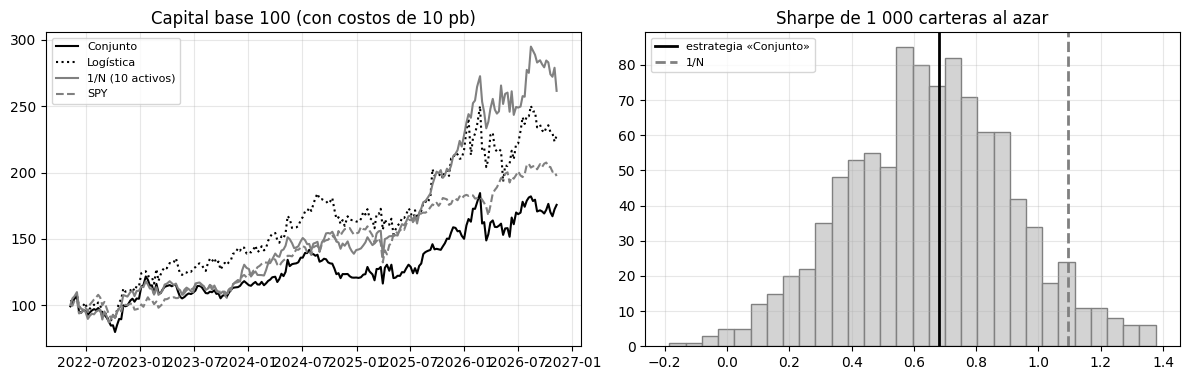

In [8]:
# Curva de capital (base 100) de la estrategia y de las referencias, y distribución del Sharpe del azar
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
for n, c, ls in [
    ("Conjunto", "black", "-"),
    ("Logística", "black", ":"),
    ("1/N (10 activos)", "gray", "-"),
    ("SPY", "gray", "--"),
]:
    ax[0].plot((1 + semanal[n].fillna(0)).cumprod() * 100, color=c, ls=ls, label=n)
ax[0].set_title("Capital base 100 (con costos de 10 pb)")
ax[0].legend(fontsize=8)
ax[1].hist(sh_azar, bins=30, color="lightgray", edgecolor="gray")
ax[1].axvline(
    tabla_bt.loc["Conjunto", "Sharpe"],
    color="black",
    lw=2,
    label="estrategia «Conjunto»",
)
ax[1].axvline(
    tabla_bt.loc["1/N (10 activos)", "Sharpe"], color="gray", lw=2, ls="--", label="1/N"
)
ax[1].set_title("Sharpe de 1 000 carteras al azar")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 5. La recomendación de hoy (corte: cierre del 19-nov-2026)
Se entrena con **todas** las filas con objetivo conocido y se predice la **última fecha**. La señal es una regla simple y declarada: **COMPRAR** = los 3 activos con mayor probabilidad y probabilidad ≥ 0,50; **EVITAR** = los 3 con menor probabilidad; **MANTENER** = el resto. Además, el **semáforo del mercado**: la probabilidad de alta volatilidad y de caída extrema de SPY (Guías 1 y 4).

In [9]:
# Recomendación a la última fecha con variables
ultima = panel_x.index.get_level_values("fecha").max()
hoy = panel_x.loc[ultima]
entr = panel
ajustados = {n: f().fit(entr[VARS], entr["y"]) for n, f in modelos.items()}
rec = pd.DataFrame(
    {n: m.predict_proba(hoy[VARS])[:, 1] for n, m in ajustados.items()}, index=hoy.index
)
rec["Conjunto"] = rec.mean(axis=1)
rec = rec.sort_values("Conjunto", ascending=False)
rec["señal"] = "MANTENER"
rec.loc[rec.index[:3], "señal"] = "COMPRAR"
rec.loc[rec.index[-3:], "señal"] = "EVITAR"
rec.loc[(rec["señal"] == "COMPRAR") & (rec["Conjunto"] < 0.5), "señal"] = "MANTENER"
rec["nombre"] = [NOMBRES.get(t, t) for t in rec.index]
print("Fecha de corte:", ultima.date())
print(rec[["nombre", "Logística", "XGBoost", "Conjunto", "señal"]].round(3).to_string())

Fecha de corte: 2026-11-19
                     nombre  Logística  XGBoost  Conjunto     señal
activo                                                             
BVN     Buenaventura (Perú)      0.512    0.624     0.568   COMPRAR
SCCO        Southern Copper      0.523    0.569     0.546   COMPRAR
FSM          Fortuna Mining      0.498    0.556     0.527   COMPRAR
XOM              ExxonMobil      0.508    0.544     0.526  MANTENER
BHP                     BHP      0.501    0.538     0.519  MANTENER
B            Barrick Mining      0.497    0.541     0.519  MANTENER
PFE                  Pfizer      0.507    0.506     0.507  MANTENER
KO                Coca-Cola      0.507    0.485     0.496    EVITAR
JPM                JPMorgan      0.494    0.490     0.492    EVITAR
AAPL                  Apple      0.498    0.472     0.485    EVITAR


In [10]:
# Semáforo del mercado con SPY: probabilidad de alta volatilidad (22 sesiones) y de caída extrema (10 sesiones) con el modelo de las Guías 1 y 4
c = cierres["SPY"].dropna()
a, b, v = (
    altos["SPY"].reindex(c.index),
    bajos["SPY"].reindex(c.index),
    volumenes["SPY"].reindex(c.index),
)
vx = cierres["^VIX"].reindex(c.index).ffill()
rr = np.log(c).diff() * 100
Xm = pd.DataFrame(
    {
        "ret_1": rr,
        "ret_5": rr.rolling(5).sum(),
        "ret_22": rr.rolling(22).sum(),
        "vol_5": rr.rolling(5).std(),
        "vol_22": rr.rolling(22).std(),
        "vol_66": rr.rolling(66).std(),
        "vix": vx,
        "d_vix": vx.diff(5),
        "dist_sma50": (c / c.rolling(50).mean() - 1) * 100,
        "rango_22": (c - b.rolling(22).min())
        / (a.rolling(22).max() - b.rolling(22).min()),
    }
).loc["2012-01-01":]
vol_f = rr.shift(-22).rolling(22).std()
caida = pd.concat([c.shift(-k) / c - 1 for k in range(1, 11)], axis=1).min(axis=1)
dm = Xm.join(vol_f.rename("vol_fut")).join(caida.rename("caida"))
ent_m = dm.dropna()
umbral_v = ent_m["vol_fut"].quantile(0.70)
m_v = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    ent_m[Xm.columns], (ent_m["vol_fut"] > umbral_v).astype(int)
)
m_c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    ent_m[Xm.columns], (ent_m["caida"] <= -0.04).astype(int)
)
x_hoy = Xm.iloc[[-1]]
p_vol, p_crash = float(m_v.predict_proba(x_hoy)[0, 1]), float(
    m_c.predict_proba(x_hoy)[0, 1]
)
print(
    "SPY al",
    Xm.index[-1].date(),
    "| VIX:",
    round(float(x_hoy["vix"].iloc[0]), 2),
    "| P(alta volatilidad próximas 22 sesiones):",
    round(p_vol, 3),
    "| P(caída ≥ 4 % en 10 sesiones):",
    round(p_crash, 3),
    "| tasas base históricas:",
    round(float((ent_m["vol_fut"] > umbral_v).mean()), 3),
    "y",
    round(float((ent_m["caida"] <= -0.04).mean()), 3),
)

SPY al 2026-11-19 | VIX: 28.44 | P(alta volatilidad próximas 22 sesiones): 0.906 | P(caída ≥ 4 % en 10 sesiones): 0.204 | tasas base históricas: 0.3 y 0.097


In [11]:
# Exportación al tablero: JSON (con todo lo que muestra la página) y CSV de recomendaciones
equidad = {
    n: [round(float(x), 3) for x in (1 + semanal[n].fillna(0)).cumprod() * 100]
    for n in ["Conjunto", "Logística", "1/N (10 activos)", "SPY"]
}
salida = {
    "fecha_corte": str(ultima.date()),
    "portafolio": PORTAFOLIO,
    "aviso": "Material educativo; no es asesoría de inversión.",
    "semaforo": {
        "vix": round(float(x_hoy["vix"].iloc[0]), 2),
        "p_alta_volatilidad_22": round(p_vol, 3),
        "p_caida_extrema_10": round(p_crash, 3),
    },
    "recomendaciones": [
        {
            "activo": t,
            "nombre": r["nombre"],
            "p_logistica": round(float(r["Logística"]), 3),
            "p_xgboost": round(float(r["XGBoost"]), 3),
            "p_conjunto": round(float(r["Conjunto"]), 3),
            "senal": r["señal"],
        }
        for t, r in rec.iterrows()
    ],
    "backtest": {
        "fechas": [str(f.date()) for f in semanal.index],
        "equidad": equidad,
        "metricas": {
            n: {k: round(float(v), 2) for k, v in fila.items()}
            for n, fila in tabla_bt.iterrows()
        },
        "sharpe_azar": {
            "media": round(float(sh_azar.mean()), 2),
            "p5": round(float(np.percentile(sh_azar, 5)), 2),
            "p95": round(float(np.percentile(sh_azar, 95)), 2),
        },
    },
}
with open("dashboard_clasificacion.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False)
rec.round(4).to_csv("recomendaciones_5_sesiones.csv", encoding="utf-8")
print(
    "Escritos: dashboard_clasificacion.json y recomendaciones_5_sesiones.csv |",
    len(rec),
    "recomendaciones",
)

Escritos: dashboard_clasificacion.json y recomendaciones_5_sesiones.csv | 10 recomendaciones


# 6. Resumen
- Un clasificador se vuelve **sistema** con tres piezas: una **regla** (top-3 con umbral), **costos** y **referencias** (1/N, SPY, azar).
- **Walk-forward** con embargo evita mirar el futuro; el **percentil frente a carteras al azar** dice si el resultado se distingue de la suerte.
- La recomendación es una **probabilidad condicional**, no una promesa: se entrega con el semáforo de mercado y la advertencia de que no es asesoría de inversión.